# Agricultural Climate Indicators and Seasonal Windows

In agrometeorology and crop modeling, climatic risks and crop development rarely follow calendar months or calendar years. Instead, they depend on **phenological windows and biological thresholds**:
- **Active growing seasons** (for example, April 1 to October 31 in the Northern Hemisphere).
- **Winter dormancy and vernalisation periods** crossing year boundaries (for example, October 1 to March 31).
- **Critical physiological thresholds**, such as base temperatures for thermal accumulation, chilling requirements, and extreme heat-stress thresholds during flowering or grain-filling.

**earthkit-climate** provides native agricultural indicators and specialized seasonal engines (`CEI` - Condition Excess Index and `CDI` - Crop Deficit Indicator) that handle:
1. Dynamic seasonal boundaries (including cross-year periods and leap years).
2. Multi-day spell and streak requirements (such as persistent heatwaves).
3. Dual output formats (clean `xarray.DataArray` or full diagnostic `xarray.Dataset`).

This guide demonstrates how to calculate, configure, and visualize these indicators using sample data loaded through `earthkit-data`.

## 1. Loading Agricultural Sample Data with earthkit-data

We load the `synthetic-daily-agro` sample dataset via `earthkit.data.from_source()`. This dataset provides 3 years (2020-2022) of daily mean temperature (`tas`), maximum temperature (`tasmax`), and solar radiation (`rsds`):

In [1]:
import earthkit.data as ekd
import matplotlib.pyplot as plt

import earthkit.climate.indicators as indicators

ds = ekd.from_source("earthkit-climate-sample", "synthetic-daily-agro").to_xarray()
ds

/home/cuadradot/predictia_projects/git/c3s-indices/earthkit-climate/src/earthkit/climate/_sample_source.py:387: UserWarning: earthkit-climate-sample datasets are made available for demonstration purposes only. Files are not guaranteed to be available long-term and may change over time. Please use official channels to obtain the contained datasets reliably for other purposes.
  warnings.warn(


<xarray.Dataset> Size: 35kB
Dimensions:  (time: 1096)
Coordinates:
  * time     (time) datetime64[ns] 9kB 2020-01-01 2020-01-02 ... 2022-12-31
Data variables:
    tas      (time) float64 9kB 2.764 -0.5929 3.892 4.38 ... 2.46 0.3626 5.066
    tasmax   (time) float64 9kB 7.24 7.046 12.78 9.971 ... 7.726 7.889 9.402
    rsds     (time) float64 9kB 82.08 62.6 112.6 74.95 ... 63.56 66.48 62.46

## 2. Crop Growth and Thermal Accumulation

### Growing Degree Days (GDD)
Growing degree days quantify the heat accumulated above a crop base temperature ($T_{\text{base}}$) during the growing season:

In [2]:
gdd = indicators.growing_degree_days_season(
    tas=ds.tas,
    season_start="04-01",
    season_end="10-31",
    tbase=10.0,
)
print("Indicator name:", gdd.name)
print("Units:", gdd.attrs.get("units"))
print("Long name:", gdd.attrs.get("long_name"))
gdd

Indicator name: cum_excess
Units: degC d
Long name: Growing Degree Days (Season 04-01 to 10-31, Tbase = 10.0 degC)


<xarray.DataArray 'cum_excess' (time: 1096)> Size: 9kB
array([0., 0., 0., ..., 0., 0., 0.], shape=(1096,))
Coordinates:
  * time       (time) datetime64[ns] 9kB 2020-01-01 2020-01-02 ... 2022-12-31
    season_id  (time) float64 9kB nan nan nan nan nan ... nan nan nan nan nan
Attributes:
    units:          degC d
    standard_name:  air_temperature
    cell_methods:   time: mean within days
    long_name:      Growing Degree Days (Season 04-01 to 10-31, Tbase = 10.0 ...

### Degree Days for Agricultural Pests
Accumulates thermal excess for pest development cycles over the active season:

In [3]:
pdd = indicators.pest_degree_days(
    tas=ds.tas,
    season_start="04-01",
    season_end="10-31",
    tbase=10.0,
)
pdd

<xarray.DataArray 'cum_excess' (time: 1096)> Size: 9kB
array([0., 0., 0., ..., 0., 0., 0.], shape=(1096,))
Coordinates:
  * time       (time) datetime64[ns] 9kB 2020-01-01 2020-01-02 ... 2022-12-31
    season_id  (time) float64 9kB nan nan nan nan nan ... nan nan nan nan nan
Attributes:
    units:          degC d
    standard_name:  air_temperature
    cell_methods:   time: mean within days
    long_name:      Degree-Days for Pests (Tbase = 10.0 degC)

## 3. Winter Phenology: Dormancy and Vernalisation (Cross-Year Seasons)

Many temperate fruits and winter crops require specific thermal windows during winter dormancy. These seasons cross calendar-year boundaries (for example, from October 1 to March 31 of the next year).

### Chilling Hours
Calculates accumulated hours within the dormant thermal window (default 0 to 7.2°C):

In [4]:
chill = indicators.chilling_hours(
    tas=ds.tas,
    season_start="10-01",
    season_end="03-31",
    lower=0.0,
    upper=7.2,
)
chill

<xarray.DataArray 'cum_excess' (time: 1096)> Size: 9kB
array([ 1.,  1.,  2., ..., 49., 50., 51.], shape=(1096,))
Coordinates:
  * time       (time) datetime64[ns] 9kB 2020-01-01 2020-01-02 ... 2022-12-31
    season_id  (time) float64 9kB 1.0 1.0 1.0 1.0 1.0 ... 4.0 4.0 4.0 4.0 4.0
Attributes:
    units:          h
    standard_name:  air_temperature
    cell_methods:   time: mean within days
    long_name:      Chilling Hours (0 to 7.2 degC model)

### Vernalisation Days
Counts winter days within the optimal vernalisation range (-1 to 7°C) required for winter cereals:

In [5]:
vern = indicators.vernalisation_days(
    tas=ds.tas,
    season_start="10-01",
    season_end="03-31",
    lower=-1.0,
    upper=7.0,
)
vern

<xarray.DataArray 'cum_excess' (time: 1096)> Size: 9kB
array([ 1.,  2.,  3., ..., 48., 49., 50.], shape=(1096,))
Coordinates:
  * time       (time) datetime64[ns] 9kB 2020-01-01 2020-01-02 ... 2022-12-31
    season_id  (time) float64 9kB 1.0 1.0 1.0 1.0 1.0 ... 4.0 4.0 4.0 4.0 4.0
Attributes:
    units:          d
    standard_name:  air_temperature
    cell_methods:   time: mean within days
    long_name:      Vernalisation Requirement Days

## 4. Monitoring Crop Heat Stress and Heatwaves

Extreme temperatures during reproductive and flowering phases can cause pollination failure and severe yield loss.

### Heat-Stress Days
Counts days exceeding the critical temperature threshold ($T_{\text{max}} \ge 32^\circ\text{C}$):

In [6]:
heat_stress = indicators.heat_stress_days(
    tasmax=ds.tasmax,
    season_start="05-01",
    season_end="09-30",
    thresh=32.0,
)
print("Max cumulative heat-stress days in season:", int(heat_stress.max().values))
heat_stress

Max cumulative heat-stress days in season: 42


<xarray.DataArray 'cum_days' (time: 1096)> Size: 9kB
array([0., 0., 0., ..., 0., 0., 0.], shape=(1096,))
Coordinates:
  * time       (time) datetime64[ns] 9kB 2020-01-01 2020-01-02 ... 2022-12-31
    season_id  (time) float64 9kB nan nan nan nan nan ... nan nan nan nan nan
Attributes:
    units:          d
    standard_name:  air_temperature
    cell_methods:   time: maximum within days
    long_name:      Heat-Stress Days (Tmax >= 32.0 degC)

### Heatwave Duration in Crop Season
Counts days belonging to persistent heat spells of at least 3 consecutive days:

In [7]:
hw_duration = indicators.heatwave_duration_season(
    tasmax=ds.tasmax,
    season_start="05-01",
    season_end="09-30",
    thresh=32.0,
    min_duration=3,
)
hw_duration

<xarray.DataArray 'cum_days' (time: 1096)> Size: 9kB
array([0., 0., 0., ..., 0., 0., 0.], shape=(1096,))
Coordinates:
  * time       (time) datetime64[ns] 9kB 2020-01-01 2020-01-02 ... 2022-12-31
    season_id  (time) float64 9kB nan nan nan nan nan ... nan nan nan nan nan
Attributes:
    units:          d
    standard_name:  air_temperature
    cell_methods:   time: maximum within days
    long_name:      Heatwave Duration (Tmax >= 32.0 degC, min_duration >= 3 d)

## 5. Solar Radiation Integration

Accumulates incoming solar shortwave radiation over the photosynthetic active season:

In [8]:
solar = indicators.cumulative_shortwave_radiation(
    rsds=ds.rsds,
    season_start="04-01",
    season_end="10-31",
)
solar

<xarray.DataArray 'cum_excess' (time: 1096)> Size: 9kB
array([0., 0., 0., ..., 0., 0., 0.], shape=(1096,))
Coordinates:
  * time       (time) datetime64[ns] 9kB 2020-01-01 2020-01-02 ... 2022-12-31
    season_id  (time) float64 9kB nan nan nan nan nan ... nan nan nan nan nan
Attributes:
    units:          W m-2 d
    standard_name:  surface_downwelling_shortwave_flux_in_air
    cell_methods:   time: mean within days
    long_name:      Cumulative Shortwave Radiation

## 6. Accessing Diagnostic Datasets with `return_dataset=True`

Setting `return_dataset=True` returns the full diagnostic dataset from the underlying engine (`CEI` or `CDI`), including:
- `cond`: Boolean mask of threshold fulfillment.
- `valid`: Boolean mask indicating qualifying runs (respecting minimum duration).
- `excess`: Instantaneous daily exceedance value.
- `cum_excess` (or `cum_days`): Cumulative seasonal progression.

In [9]:
diag_ds = indicators.growing_degree_days_season(
    tas=ds.tas,
    season_start="04-01",
    season_end="10-31",
    tbase=10.0,
    return_dataset=True,
)
diag_ds

<xarray.Dataset> Size: 53kB
Dimensions:     (time: 1096)
Coordinates:
  * time        (time) datetime64[ns] 9kB 2020-01-01 2020-01-02 ... 2022-12-31
    season_id   (time) float64 9kB nan nan nan nan nan ... nan nan nan nan nan
Data variables:
    cond        (time) float64 9kB 0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
    valid       (time) float64 9kB 0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
    excess      (time) float64 9kB 0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
    cum_excess  (time) float64 9kB 0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
Attributes:
    index:         CEI
    season_start:  04-01
    season_end:    10-31
    lower:         10.0
    upper:         inf
    direction:     above
    min_duration:  1
    na_action:     false
    reference:     Begueria et al. (2026)

## 7. Visualizing Seasonal Indicators

We can plot the cumulative seasonal curves to monitor thermal accumulation and stress build-up over time:

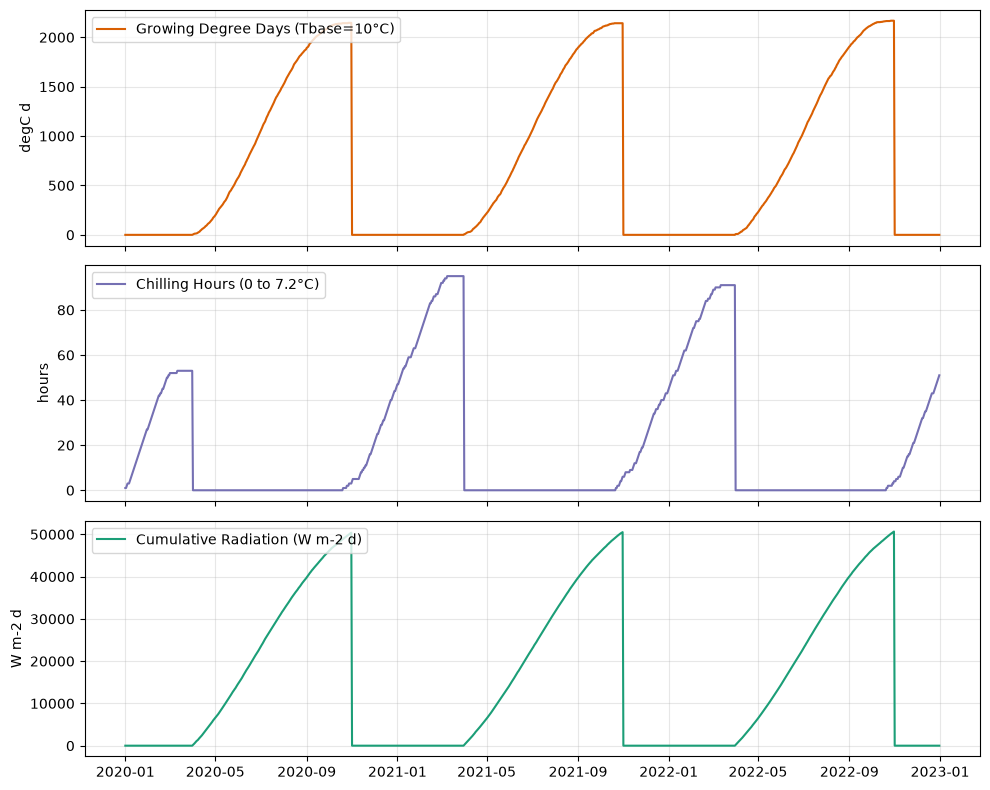

In [10]:
fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)

# GDD trajectory
axes[0].plot(ds.time, gdd.values, color="#d95f02", lw=1.5, label="Growing Degree Days (Tbase=10°C)")
axes[0].set_ylabel("degC d")
axes[0].legend(loc="upper left")
axes[0].grid(True, alpha=0.3)

# Chilling hours trajectory
axes[1].plot(ds.time, chill.values, color="#7570b3", lw=1.5, label="Chilling Hours (0 to 7.2°C)")
axes[1].set_ylabel("hours")
axes[1].legend(loc="upper left")
axes[1].grid(True, alpha=0.3)

# Cumulative solar radiation
axes[2].plot(ds.time, solar.values, color="#1b9e77", lw=1.5, label="Cumulative Radiation (W m-2 d)")
axes[2].set_ylabel("W m-2 d")
axes[2].legend(loc="upper left")
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()